In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud, STOPWORDS, ImageColorGenerator

from numpy import array
import numpy as np
from tensorflow.keras.preprocessing.text import one_hot
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten,Embedding,Dense

from gensim.models import Word2Vec
import gensim
from nltk.tokenize import sent_tokenize, word_tokenize
import warnings
import nltk
nltk.download('punkt')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\diego\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!


True

In [3]:
df=pd.read_csv("data/listings.csv")
df.head(10)

C:\Users\diego\anaconda3\lib\site-packages\IPython\core\interactiveshell.py:3444: DtypeWarning: Columns (61,62,94) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


,id,listing_url,scrape_id,last_scraped,name,summary,space,description,experiences_offered,neighborhood_overview,...,instant_bookable,is_business_travel_ready,cancellation_policy,require_guest_profile_picture,require_guest_phone_verification,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,17878,https://www.airbnb.com/rooms/17878,20190715155027,2019-07-16,Very Nice 2Br - Copacabana - WiFi,Please note that special rates apply for Carni...,- large balcony which looks out on pedestrian ...,Please note that special rates apply for Carni...,none,This is the best spot in Rio. Everything happe...,...,t,f,strict_14_with_grace_period,f,f,1,1,0,0,2.13
1,25026,https://www.airbnb.com/rooms/25026,20190715155027,2019-07-16,Beautiful Modern Decorated Studio in Copa,"Our apartment is a little gem, everyone loves ...",This newly renovated studio (last renovations ...,"Our apartment is a little gem, everyone loves ...",none,Copacabana is a lively neighborhood and the ap...,...,f,f,strict_14_with_grace_period,t,t,3,3,0,0,2.09
2,31560,https://www.airbnb.com/rooms/31560,20190715155027,2019-07-16,NICE & COZY 1BDR - IPANEMA BEACH,This nice and clean 1 bedroom apartment is loc...,This nice and clean 1 bedroom apartment is loc...,This nice and clean 1 bedroom apartment is loc...,none,Die Nachbarschaft von Ipanema ist super lebend...,...,t,f,strict_14_with_grace_period,f,f,1,1,0,0,2.37
3,35636,https://www.airbnb.com/rooms/35636,20190715155027,2019-07-16,Cosy flat close to Ipanema beach,This cosy apartment is just a few steps away ...,"The location is extremely convenient, safe and...",This cosy apartment is just a few steps away ...,none,The apartment street is very quiet and safe ....,...,f,f,strict_14_with_grace_period,t,t,1,1,0,0,2.29
4,35764,https://www.airbnb.com/rooms/35764,20190715155027,2019-07-16,COPACABANA SEA BREEZE - RIO,Our newly renovated studio is located in the b...,"FEEL LIKE YOUR HOME LIVING AS ""CARIOCA"" LOCAL ...",Our newly renovated studio is located in the b...,none,Our guests will experience living with a local...,...,t,f,strict_14_with_grace_period,f,t,1,1,0,0,2.83
5,35893,https://www.airbnb.com/rooms/35893,20190715155027,2019-07-16,Copa Tabajaras,"Very quiet flat, with view on tropical jungle ...","Purpose of CopaTabajaras is to provide a nice,...","Very quiet flat, with view on tropical jungle ...",none,"Copacabana is the heart of Rio de Janeiro, wit...",...,f,f,moderate,f,f,1,0,1,0,0.01
6,48305,https://www.airbnb.com/rooms/48305,20190715155027,2019-07-16,"Beach Block 6bed Penthouse, Ipanema Best Locat...","Sunny terrace with side ocean view, 6 ensuite ...",••• WHY AND HOW WE DIFFER ••• Our guest loves ...,"Sunny terrace with side ocean view, 6 ensuite ...",none,"Located right on Ipanema Beach, Posto 9, only ...",...,t,f,strict_14_with_grace_period,f,f,6,4,2,0,0.53
7,48726,https://www.airbnb.com/rooms/48726,20190715155027,2019-07-15,Rio de Janeiro Copacabana Ipanema,"Apartamento tem três dormitórios, dois banheir...",Excelente acomodação perto da praia mais famos...,"Apartamento tem três dormitórios, dois banheir...",none,"Amo a paisagem, arvores a proximidade da praia...",...,t,f,strict_14_with_grace_period,f,f,1,0,1,0,1.94
8,48901,https://www.airbnb.com/rooms/48901,20190715155027,2019-07-16,4bedrooms Copacabana Beach,Excellent and great 4 bedroom apartment ( one ...,Plenty of space on 150 sq. meters. Large room...,Excellent and great 4 bedroom apartment ( one ...,none,Great traditional distric. Lively and cool. Fr...,...,t,f,strict_14_with_grace_period,f,f,5,5,0,0,0.06
9,48902,https://www.airbnb.com/rooms/48902,20190715155027,2019-07-16,HUmaita 1 quarto ate 3 pessoas 1 Bedroom 3 sleep,Very Quiet bedroom with a double bed ideal for...,Very picturesk cobblestone street (dead end) q...,Very Quiet bedroom with a double bed ideal for...,none,NaN,...,f,f,strict_14_with_grace_period,f,f,5,5,0,0,NaN


In [177]:
df.dropna(subset=['summary'], axis=0, inplace = True)
summary = df['summary'].head(1000)
summary

0       Please note that special rates apply for Carni...
1       Our apartment is a little gem, everyone loves ...
2       This nice and clean 1 bedroom apartment is loc...
3       This cosy apartment  is just a few steps away ...
4       Our newly renovated studio is located in the b...
                              ...                        
1346    Excelente apartamento de 2 quartos com 120metr...
1347    Cozy, bright and well ventilated flat, with fu...
1348    Beautiful double room, recently renovated, wit...
1349    If you are coming to Rio here is the right spo...
1350    Charming two-bedroom apartment, totally refurb...
Name: summary, Length: 1000, dtype: object

In [178]:
all_summary = " ".join(s for s in summary)
#all_summary

In [171]:
stopwords = set(STOPWORDS)
stopwords.update(["da", "meu", "em", "você", "de", "ao", "os"])

## Data Prep

In [172]:
import re

In [244]:

data=[]
stopwords = set(STOPWORDS)
stopwords.update(["da", "meu", "em", "você", "de", "ao", "os",
                      "and","the","a","in","to","with","de","e","for",""])
# iterate through each sentence in the file
for review in summary.to_list():
    data_temp = []
    for i in sent_tokenize(review):
        temp = []

        # tokenize the sentence into words
        for j in word_tokenize(i):
            j = re.sub(u'[^a-zA-ZáéíóúÁÉÍÓÚâêîôÂÊÎÔãõÃÕçÇ:]', '',j)
            if not j.lower() in stopwords:
                    temp.append(j.lower())

        #data.append(np.array(temp).flatten())
        data_temp.append(' '.join(temp))
        
    data.append(' '.join(data_temp))

#### Embedding

In [256]:
# Create Skip gram model
model1 = gensim.models.Word2Vec([word.split(' ') for word in data ], min_count=1,
                                vector_size=100, window=5,sg=2)
words = list(w for w in model1.wv.index_to_key)

In [257]:

# Make a dictionary
we_dict = {word:model1.wv[word] for word in words}
df_vectors=pd.DataFrame(we_dict).transpose()

In [258]:
df_vectors

,0,1,2,3,4,5,6,7,8,9,...,90,91,92,93,94,95,96,97,98,99
beach,-0.236770,0.528167,0.032244,0.043227,0.285227,-0.574966,-0.003684,0.820251,-0.153626,-0.081206,...,0.287138,0.168964,0.265440,0.088411,0.915251,0.376758,-0.109921,-0.119773,-0.103486,-0.192793
copacabana,-0.197330,0.419127,0.045527,0.094147,0.235841,-0.459728,0.057566,0.717585,-0.140668,-0.022608,...,0.306879,0.131455,0.202091,0.022407,0.763250,0.333893,-0.057261,-0.117503,-0.096127,-0.165518
rio,-0.172911,0.294514,0.113838,0.005351,0.135950,-0.313672,0.118730,0.550002,-0.210777,-0.066259,...,0.310921,0.148674,0.158805,0.055200,0.641195,0.371770,0.010780,-0.158232,0.036719,-0.192695
apartment,-0.234934,0.503618,0.150257,-0.095443,0.254588,-0.586783,-0.090460,0.740847,-0.242423,-0.298778,...,0.154904,0.176659,0.239420,0.233715,0.751314,0.238568,0.006383,-0.224952,0.050360,-0.201946
ipanema,-0.189680,0.406079,0.016934,0.091458,0.225837,-0.460121,0.044770,0.681255,-0.123552,0.037530,...,0.325611,0.119753,0.199039,-0.001020,0.756243,0.312317,-0.040623,-0.118001,-0.117991,-0.158937
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
punto,-0.043831,0.035299,0.044735,0.011582,-0.010741,-0.084700,0.015155,0.126248,-0.063285,-0.012197,...,0.062213,0.029779,0.007193,0.019581,0.094196,0.032450,0.000469,-0.073927,0.015955,-0.018493
cualquer,-0.040008,0.033995,0.040156,0.019651,-0.018726,-0.097579,0.017554,0.119173,-0.059359,-0.010269,...,0.072797,0.034264,0.025397,0.028740,0.111880,0.054059,0.011949,-0.069659,0.018397,-0.029119
directo,-0.051413,0.049706,0.055775,0.019124,-0.017407,-0.095263,0.032137,0.157192,-0.075401,-0.034256,...,0.087561,0.039987,0.019034,0.037192,0.115037,0.066337,0.016538,-0.088134,0.012572,-0.019981
auobuses,-0.052303,0.040501,0.057528,0.002354,-0.016550,-0.092185,0.028918,0.154621,-0.068845,-0.034845,...,0.080232,0.027803,0.014774,0.022197,0.120337,0.048824,0.014710,-0.090020,0.030384,-0.027379


#### BoW TF idf

In [184]:
!pip install scikit-learn==1.2.2

  Attempting uninstall: joblib
    Found existing installation: joblib 1.1.0
    Uninstalling joblib-1.1.0:
      Successfully uninstalled joblib-1.1.0
  Attempting uninstall: scikit-learn
    Found existing installation: scikit-learn 0.24.2
    Uninstalling scikit-learn-0.24.2:
      Successfully uninstalled scikit-learn-0.24.2


ERROR: Could not install packages due to an OSError: [WinError 5] Acesso negado: 'C:\\Users\\diego\\anaconda3\\Lib\\site-packages\\~klearn\\cluster\\_dbscan_inner.cp39-win_amd64.pyd'
Consider using the `--user` option or check the permissions.



In [185]:
from sklearn.feature_extraction.text import TfidfVectorizer,CountVectorizer
from sklearn.decomposition import PCA

In [250]:
tfidf_vectorizer=TfidfVectorizer(min_df=10)
text_idf=tfidf_vectorizer.fit_transform(data)

count_vectorizer=CountVectorizer(min_df=10)
text_count=count_vectorizer.fit_transform(data)

In [252]:
data

['please note special rates apply carnival usually host groups people prefer rent minimum stay nights please contact discuss beautiful sunny bedroom square meters h doorman building min walk copacabana beach spacious living room bedrooms fullsize beds sleeps high speed wifi mb phone local landline calls free',
 'apartment little gem everyone loves staying best location blocks subway blocks beach close bars restaurants supermarket banks public transportation need wifi cable tv air con fan',
 'nice clean bedroom apartment located best area rio : blocks ipanema beach posto right next leblon lagoa perfect want feel local real carioca',
 'cosy apartment steps away famous copacabana walking distance stunning ipanema beach main attractions city located arpoador lovely building hours doorman security',
 'newly renovated studio located best part copacabana posto posto minutes arpoador ipanema beach security hours day enjoy stay family bulding living local people',
 'quiet flat view tropical jun

In [251]:
df_vectors=pd.DataFrame(
    text_idf.todense(),
    columns=tfidf_vectorizer.get_feature_names()
).transpose()
pca = PCA(n_components=50)

df_vectors = pd.DataFrame(
    pca.fit_transform(df_vectors),
    index=df_vectors.index
)
df_vectors



,0,1,2,3,4,5,6,7,8,9,...,40,41,42,43,44,45,46,47,48,49
ac,0.108593,0.016370,-0.114836,0.242765,-0.078903,0.002374,-0.062349,-0.107114,0.004816,-0.036528,...,0.009191,-0.047245,0.022139,-0.012886,0.013719,0.015815,-0.081433,0.098389,0.059625,-0.035537
access,0.235235,-0.001966,-0.058552,-0.041424,0.049382,-0.029944,0.033862,0.076036,-0.006436,-0.032889,...,0.069757,-0.062884,0.028637,-0.083778,-0.069781,-0.180120,0.060504,-0.090346,0.121449,-0.057055
acesso,-0.264524,-0.099325,0.038969,0.005007,0.021467,-0.020628,0.042462,-0.028142,-0.009680,0.034748,...,0.046140,0.006944,-0.013704,0.044336,0.018028,0.010794,0.073805,0.010589,0.081616,-0.064410
acomoda,-0.232199,-0.086835,0.032797,0.037413,-0.050511,-0.041301,0.025425,0.060767,-0.031425,0.083247,...,0.050645,-0.005411,0.029615,-0.054971,-0.128241,-0.003023,0.042731,0.013124,0.056577,0.055596
aconchegante,-0.281880,-0.142093,0.104045,0.045480,-0.015641,-0.031988,0.238704,-0.040943,0.067187,0.079254,...,-0.123838,-0.095279,0.015518,0.233953,0.365134,0.187622,0.030861,-0.024551,0.005765,-0.216894
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
zone,0.019781,0.039549,-0.080982,-0.099315,0.061817,0.011597,0.009475,-0.111202,-0.053124,-0.020536,...,-0.026273,-0.031358,0.033100,-0.000918,-0.033769,0.059177,-0.113191,0.015491,-0.015600,0.009749
área,-0.284243,-0.124424,0.068141,0.018526,0.011713,-0.022478,0.018857,-0.023787,0.014296,0.029382,...,-0.051685,-0.038484,0.029690,0.086802,0.038291,0.035010,0.072670,-0.033359,0.086695,0.065788
ótima,-0.187306,-0.035093,-0.009855,0.000796,-0.057989,-0.041223,-0.011540,0.003184,0.015668,0.036928,...,-0.048143,-0.005065,0.006082,-0.004477,0.088292,-0.059212,0.016606,-0.008016,-0.051968,-0.072361
ótimo,-0.178643,-0.009833,-0.041955,-0.029608,0.004097,-0.016158,0.035654,-0.050217,0.007852,-0.021309,...,0.027957,-0.032879,0.019506,0.017334,0.030353,0.009399,-0.002871,-0.000249,-0.032021,-0.014749


In [182]:
df_vectors=pd.DataFrame(
    pca.fit_transform(text_idf.todense().transpose()),
    index=tfidf_vectorizer.get_feature_names()
)
df_vectors

,0,1,2,3,4,5,6,7,8,9,...,40,41,42,43,44,45,46,47,48,49
00,-0.136873,-0.062730,-0.000474,-0.064701,0.016081,0.058164,0.049281,-0.049820,0.094731,-0.024073,...,0.026018,-0.003271,0.029931,-0.097475,0.008432,-0.020905,-0.026306,0.035580,-0.009995,0.018708
10,0.101458,-0.000683,-0.022405,-0.039384,0.225375,-0.063027,-0.103569,-0.024885,0.010123,0.017592,...,0.119283,-0.024912,-0.042482,-0.031144,0.032271,0.059240,0.037956,-0.111878,-0.014126,0.074480
100,-0.041293,-0.083730,-0.035828,-0.034672,0.085816,-0.061140,0.008429,-0.016635,0.017683,-0.175570,...,-0.032342,-0.154536,0.030538,0.113162,0.102078,-0.069076,0.011813,-0.086669,0.033936,-0.014381
12,-0.124985,-0.113489,-0.036282,-0.031736,0.024755,0.058850,0.037020,0.034547,0.038667,-0.045217,...,-0.022316,-0.002026,0.021704,-0.032176,-0.014144,-0.057991,-0.020303,0.066300,-0.019798,-0.027160
15,-0.060881,0.016153,-0.029009,-0.052519,0.112761,0.000027,-0.065257,-0.043347,0.084201,0.100691,...,-0.012096,0.052005,-0.014968,0.041072,0.064564,-0.079781,0.027728,-0.042713,-0.037797,0.027569
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
zone,-0.040811,-0.104810,-0.039337,-0.066499,-0.012162,0.014149,-0.009829,0.058921,0.113307,0.015346,...,0.013954,-0.022400,-0.037261,-0.009264,-0.038269,0.013170,-0.078867,-0.017767,-0.057238,-0.055064
área,-0.244211,0.147108,-0.007601,-0.029843,-0.028081,-0.030169,-0.009897,0.035977,-0.002843,0.006457,...,0.045098,0.044514,-0.080794,0.039965,-0.056281,0.022916,-0.033737,-0.020722,-0.095100,0.073270
ótima,-0.198666,-0.002009,-0.019894,-0.005665,-0.000094,-0.071144,0.024800,0.035548,-0.020304,0.002323,...,0.026909,0.006562,0.015585,0.024092,-0.043211,-0.090797,0.002985,0.018782,-0.027364,-0.033071
ótimo,-0.195122,-0.016051,-0.017061,-0.038403,-0.022882,-0.017435,-0.000542,0.022143,0.024556,0.013265,...,-0.004183,-0.061940,0.010409,0.014232,0.030723,0.017709,-0.000425,-0.014363,0.055798,-0.007292


In [143]:
df_count_vetors=pd.DataFrame(
    text_count.todense(),
    columns=count_vectorizer.get_feature_names()
    
)

pca = PCA(n_components=6)

df_vectors = pd.DataFrame(
    pca.fit_transform(df_vectors),
    index=df_vectors.index
)

df_vectors

## Clusterização

In [261]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps=0.01, min_samples=5,metric='cosine')
clusters=dbscan.fit_predict(df_vectors.values)     
df_vectors['clusters'] =clusters
df_words=df_vectors.reset_index()[['index','clusters']]
df_wordcloud=df_words.groupby(['clusters'])['index'].apply(lambda x: ','.join(x)).reset_index()
df_wordcloud

,clusters,index
0,-1,"rio,tv,wifi,one,metro,janeiro,two,comfortable,..."
1,0,"beach,copacabana,apartment,ipanema,para,o,room..."
2,1,"please,send,message,package,pricing,minimum,ye..."
3,2,"perfekte,térreo,amável,cembedly,belissimo,sss,..."


In [115]:
from sklearn.cluster import KMeans
import numpy as np

kmeans = KMeans(n_clusters=4, random_state=0)
clusters=kmeans.fit_predict(df_vectors.values)
df_vectors['clusters'] =clusters
df_words=df_vectors.reset_index()[['index','clusters']]
df_wordcloud=df_words.groupby(['clusters'])['index'].apply(lambda x: ','.join(x)).reset_index()

In [116]:
df_wordcloud

,clusters,index
0,0,"beach,rio,apartment,praia,walk,leblon,view,bed..."
1,1,"restaurants,blocks,bedrooms,quarto,local,:,awa..."
2,2,"ipanema,located,tv,block,best,bars,wifi,one,ca..."
3,3,"copacabana,para,location,apartamento,room,stay..."


## Visualize

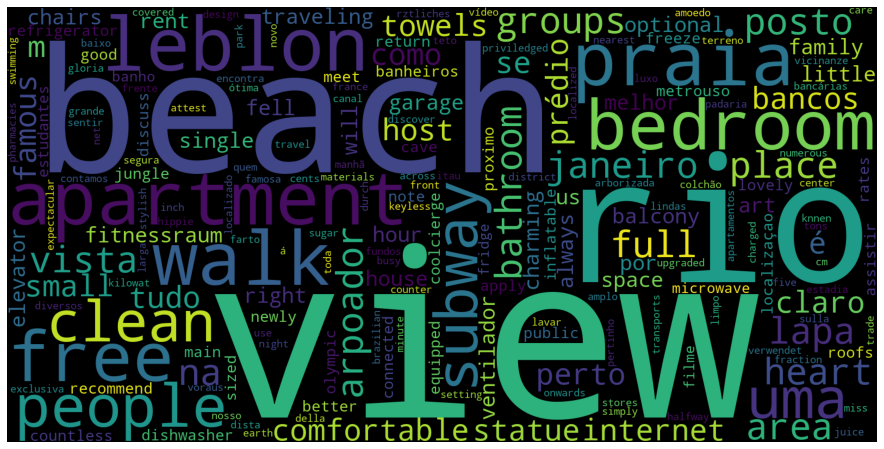

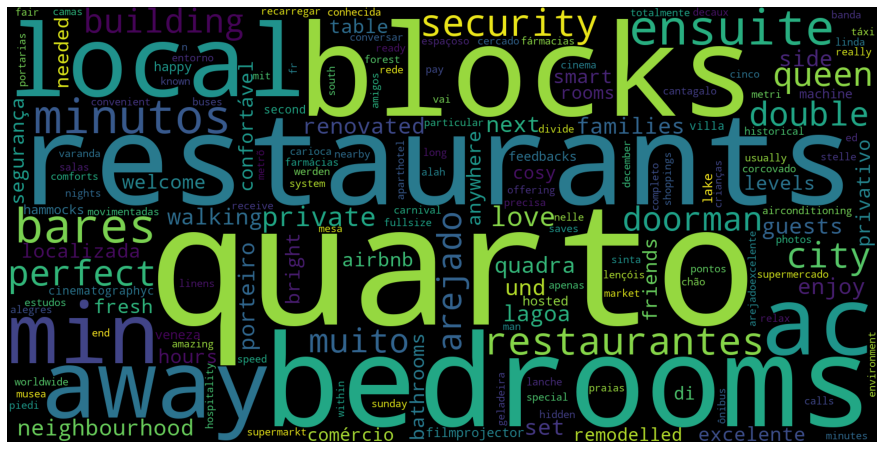

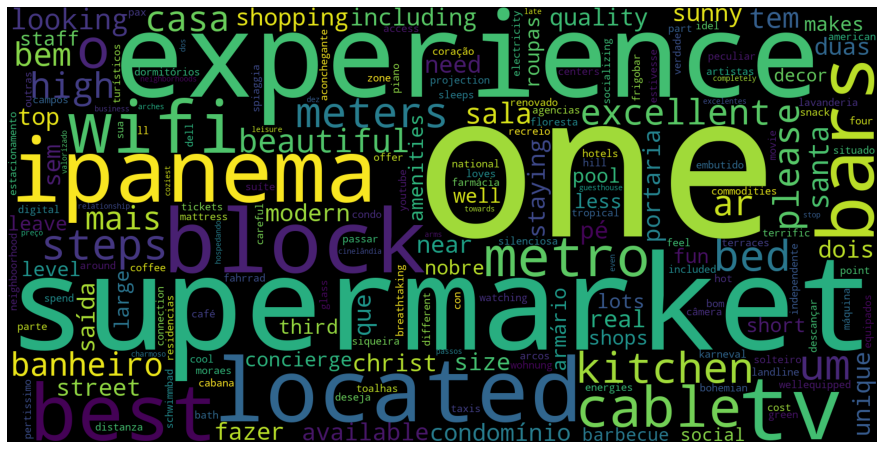

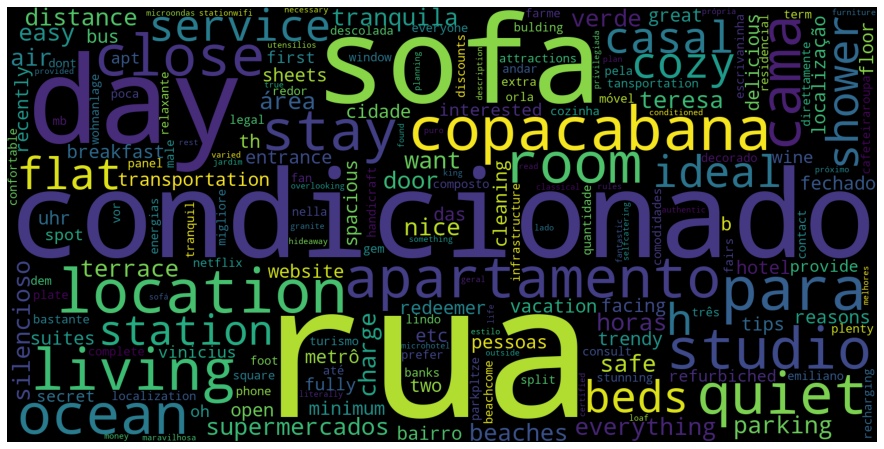

In [117]:
for words_index in df_wordcloud['index']:
    wordcloud = WordCloud(background_color='black', width=1600,                            
                          height=800).generate(words_index)
    fig, ax = plt.subplots(figsize=(16,8))            
    ax.imshow(wordcloud, interpolation='bilinear')       
    ax.set_axis_off()
    plt.imshow(wordcloud)
    #wordcloud.to_file('rafael.png',);